# TP8 — Introduction to Machine Learning

Estimated time: **1.5 hours**

In this lab, you'll work through hands-on exercises using Python to consolidate your understanding of machine learning. In particular, you'll explore learning from experience, Software 1.0, 2.0 and 3.0, and the supervised-learning pipeline. You'll train and evaluate decision-tree models for classification and regression, investigate generalization and overfitting, and examine how feature selection, training/test splits and incorrect labels can affect model performance.

## Objectives

* Get familiar with the supervised-learning dataset
* Example exercises
  * Software 1.0, Software 2.0 and Software 3.0
  * Supervised-learning pipeline for classification
  * Model performance, generalization and overfitting
  * Effect of incorrect training labels
  * Supervised-learning pipeline for regression
* Assignment questions

---

# 📚 Setup

Install required packages for this lab. `pip` will automatically skip already installed packages

In [827]:
import importlib.util

# import name: pip installation name
required_pkgs = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
}

missing_pkgs = [
    pip_name
    for import_name, pip_name in required_pkgs.items()
    if importlib.util.find_spec(import_name) is None
]

if missing_pkgs:
    print("⚠️ Missing packages:", ", ".join(missing_pkgs))
    packages = " ".join(missing_pkgs)
    %pip install $packages
else:
    print("🎉 All packages already installed.")

🎉 All packages already installed.


Import the libraries needed for the lab

In [828]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Make tables and figures easier to read.
pd.set_option("display.max_columns", 20)

# A fixed seed to allow reproducible results.
SEED = 6
print("Setup complete. Reproducibility seed:", SEED)

Setup complete. Reproducibility seed: 6


# 📊 Get familiar with the supervised-learning dataset

We create a small synthetic email dataset. Each row is one **sample**. The first five
columns describe the email and are the **features**. The final column is the known **label**.

| Column | Meaning | 
|---|---|
| `number_of_links` | number of links in the email | 
| `capital_percentage` | percentage of characters written as capitals | 
| `contains_free` | 1 if the word “free” occurs, otherwise 0 | 
| `length` | number of characters in the email | 
| `exclamation_marks` | number of `!` characters | 
| `spam` | <b>1</b> for spam, <b>0</b> for not spam |

Because the output is a category, predicting `spam` is a **classification** task.

### Synthesize the dataset

In [829]:
rng = np.random.default_rng(SEED)
n_emails = 240

emails = pd.DataFrame({
    "number_of_links": rng.poisson(lam=2.2, size=n_emails),
    "capital_percentage": np.clip(
        rng.normal(loc=18, scale=12, size=n_emails), 0, 70
    ).round(1),
    "contains_free": rng.integers(0, 2, size=n_emails),
    "length": rng.integers(30, 301, size=n_emails),
    "exclamation_marks": rng.poisson(lam=2.0, size=n_emails),
})

# Build a noisy signal to create realistic labels for this assignment.
# Every feature contains some signal, but random noise prevents a perfect pattern.
spam_score = (
    0.28 * emails["number_of_links"]
    + 0.025 * emails["capital_percentage"]
    + 1.00 * emails["contains_free"]
    + 0.002 * emails["length"]
    + 0.22 * emails["exclamation_marks"]
    + rng.normal(0, 0.75, size=n_emails)
)
emails["spam"] = (spam_score > 2.30).astype(int)

print("Dataset shape:", emails.shape)
emails.head(8)

Dataset shape: (240, 6)


,number_of_links,capital_percentage,contains_free,length,exclamation_marks,spam
0,2,41.6,0,252,3,1
1,4,38.0,1,172,2,1
2,1,15.7,1,298,1,1
3,0,34.6,0,257,3,0
4,1,0.0,0,166,3,0
5,3,29.4,1,199,3,1
6,2,27.1,0,280,2,1
7,1,30.4,0,134,1,0


### Inspect the data before learning

In [830]:
display(emails["spam"].value_counts().rename(index={0: "not spam", 1: "spam"}).to_frame("count"))

display(emails.groupby("spam").mean().rename(index={0: "not spam", 1: "spam"}).round(2))

,count
spam,
spam,123
not spam,117


,number_of_links,capital_percentage,contains_free,length,exclamation_marks
spam,,,,,
not spam,1.88,16.45,0.26,155.71,1.68
spam,2.59,19.68,0.68,188.20,2.43


The **first table** shows how many emails are in each category: spam (123) and not spam (117). The similar counts indicate a reasonably balanced dataset.

The **second table** shows the average feature values for each class. It helps reveal possible useful patterns, but they don't themselves create a model. 

# 📝 Example Exercises

## Example 1 — Learning from experience and the three software paradigms

### Example 1-1: Identify task T, performance P, and experience E for spam-email detection 

A computer program is said to learn from **experience E**, with respect to some class of **tasks T** and **performance measure P**, if its performance at tasks in T, as measured by P improves with experience E.

---

❓<span style="color:purple;">**Quick test**</span>: **For a machine-learning system that detects spam emails, identify the task (T), performance measure (P), and experience (E).**

Think about your answer before revealing the answer.

<details>
<summary>Click to reveal the answer</summary>

**Answer**:

<div style="color:blue;">

<ul>
  <li><strong>T — Task:</strong> classify a new email as spam or not spam.</li>
  <li><strong>P — Performance:</strong> the proportion of unseen emails classified correctly (accuracy).</li>
  <li><strong>E — Experience:</strong> labeled examples containing features and the correct spam/not-spam label.</li>
</ul>

</div>

</details>

---

### Example 1-2: Software 1.0 vs Software 2.0 

In [831]:
def software_1_spam_rule(row):
    # A human-written explicit rule.
    if row["contains_free"] == 1 and row["number_of_links"] >= 2:
        return 1   # spam
    return 0       # not spam

new_email = {
    "contains_free": 1,
    "number_of_links": 3,
}

prediction = software_1_spam_rule(new_email)

if prediction == 1:
    print("Prediction: spam")
else:
    print("Prediction: not spam")

Prediction: spam


<div style="border-left:5px solid #2563eb; background-color:#eff6ff;
            padding:14px 18px; margin:16px 0; border-radius:4px;">

<p style="font-size:16px; font-weight:bold; color:#1d4ed8; margin:0 0 10px 0;">
Software 1.0: human-written rules
</p>

<p>
The code above illustrates <strong>Software 1.0</strong>. A human explicitly wrote the rule:
</p>

<p style="background-color:white; padding:10px 14px; border-radius:4px;
          font-family:monospace; font-size:14px;">
<strong>IF</strong> the word “free” appears and the email contains at least two links,<br>
<strong>THEN</strong> predict spam.
</p>

<p>
The program's behavior is <strong>hand-coded and hard-coded</strong>. It is designed for this
specific task, and changing its behavior requires a programmer to modify the rules.
</p>

<hr style="border:none; border-top:1px solid #93c5fd; margin:18px 0;">

<p style="font-size:16px; font-weight:bold; color:#1d4ed8; margin:0 0 10px 0;">
Software 2.0: rules learned from data
</p>

<p>
In <strong>Software 2.0</strong>, the programmer does not manually write every decision rule.
Instead, <strong>a learning algorithm discovers rules from labeled examples</strong>. We will
examine this process in more detail later in the notebook.
</p>

</div>

### Example 1-3: Where Software 3.0 differs

With Software 3.0, we are **prompting** a foundation model that was pre-trained on massive data and can serve many tasks. 

For spam-email detection, we could write a prompt as follows: 

> <span style="color:blue"> “Classify the following email as spam or not spam and give only the label: …” </span>

We are not training a new spam-detection model in this interaction. Instead, the prompt tells the pre-trained model what behavior we want at inference time. A different prompt could ask the same model to summarize or translate the email.

| Question | Software 1.0 | Software 2.0 | Software 3.0 |
|---|---|---|---|
| What does the developer write? | explicit rules | architecture + data setup | prompt/instructions |
| Where does behavior come from? | hand-written code | task-specific training | pre-training + prompting |
| Typical scope | one coded task | one trained task | many tasks from one foundation model |

## Example 2 — A supervised-learning pipeline: Classification

In supervised learning, every training sample contains an label. The algorithm receives features and labels, learns a model, and then applies the trained model to unseen data.

In this assignment, we will use **Decision Tree** for both classification and regression, to illustrate the supervised-learning pipleline. We will not study the internal mechanics of decision trees. Instead, we will focus on the **pipeline** and the purpose of each step.

### <span style="color:blue"> Step 1 - Define the features and label</span>

| Term | Meaning in this dataset | How it is used |
|---|---|---|
| **Sample** | One email, represented by one row of the dataset | Provides one sample from which the model can learn or make a prediction |
| **Features** | `number_of_links`, `capital_percentage`, `contains_free`, `length`, and `exclamation_marks` | Serve as the input information from which the model learns patterns and makes predictions |
| **Target label** | The value in `spam` for each email: not spam (`0`) or spam (`1`) | Serves the known answer during training and evaluation and defines what the model must predict |

In [832]:
feature_names = [
    "number_of_links",
    "capital_percentage",
    "contains_free",
    "length",
    "exclamation_marks",
]

X = emails[feature_names]  # Five input features for each email
y = emails["spam"]         # One known class label for each email

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (240, 5)
y shape: (240,)


,number_of_links,capital_percentage,contains_free,length,exclamation_marks
0,2,41.6,0,252,3
1,4,38.0,1,172,2
2,1,15.7,1,298,1
3,0,34.6,0,257,3
4,1,0.0,0,166,3


Conventionally, `X` denotes the input features and `y` denotes the target label. The model is asked to learn a mapping of the form $X → y$, namely predict whether an email is spam or not, based on the features.

During **training**, the algorithm receives both the input features and the target label. It uses the features to learn patterns associated with the known labels in the training data. 

During **inference**, the model receives only the features, it must predict the label — spam or not spam.

### <span style="color:blue"> Step 2 - Reserve unseen data</span>

A model should perform well not only on the samples used for learning, but also on data it has not seen before. We therefore divide the dataset into two parts:

* **Training set:** supplied to the learning algorithm so that it can learn patterns connecting the features with the spam labels.

* **Test set:** kept separate during training and used afterwards to evaluate whether the learned patterns generalize to unseen samples.

In this example, 75% of the samples are used for training and the remaining 25% are reserved for the unseen-data evaluation.

In [833]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,   # Keep 25% of the rows for the unseen-data check
    random_state=SEED,
    stratify=y,       # Keep similar spam proportions in both parts
)

print("Training samples:", len(X_train))
print("Unseen test samples:", len(X_test))
print("Training spam proportion:", round(y_train.mean(), 3))
print("Test spam proportion:", round(y_test.mean(), 3))

Training samples: 180
Unseen test samples: 60
Training spam proportion: 0.511
Test spam proportion: 0.517


<div style="background-color:#f4f8ff;border-left:5px solid #3b82f6;border-radius:6px;padding:14px 18px;margin:12px 0;line-height:1.6;">
<b>🔧 What does the code do?</b>

<p>
<code>train_test_split()</code> divides the dataset so that 75% of the samples are used to train
the model and the remaining 25% are kept as unseen test samples for evaluation.
</p>

<ul>
  <li><code>test_size=0.25</code> reserves 25% of the samples for testing.</li>
  <li><code>random_state=SEED</code> make this particular split reproducible.</li>
  <li><code>stratify=y</code> keeps approximately the same spam/not-spam proportions in both the training set and testing set, preventing an unusually unbalanced split.</li>
</ul>
</div>

### <span style="color:blue"> Step 3 - Train a classifier</span>

A **decision-tree classifier** predicts a category by asking a sequence of simple questions
about a sample's features. 

For an email, a question might be “Is the number of links greater than 2?” or “Does it contain the word`free`?”, etc. Each answer sends the sample along one branch of the tree until it reaches a final prediction such as spam or not spam.

<div style="text-align:center;margin:16px 0;">
  <img src="decision_tree_concept.png" alt="Conceptual decision tree for spam classification" style="max-width:900px;width:100%;border:1px solid #e5e7eb;border-radius:6px;">
</div>

During training, `DecisionTreeClassifier` examines the labeled samples and learns which feature
questions and numerical thresholds help separate the classes. The programmer selects the model
family and its hyperparameters, but does not manually write the decision rules.

Here, `max_depth=3` limits the tree to at most three levels of decisions. This keeps the first
model relatively simple and makes its learned behavior easier to compare with more flexible
trees later in the notebook. 

In [834]:
classifier = DecisionTreeClassifier(max_depth=3, random_state=SEED)

# fit() is the training phase: the algorithm uses labeled samples.
classifier.fit(X_train, y_train)

# predict() is inference: the trained model is run on unseen feature rows.
test_predictions = classifier.predict(X_test)

print("First 10 predictions:", test_predictions[:10])
print("First 10 answers:    ", y_test.to_numpy()[:10])

First 10 predictions: [1 1 0 0 1 1 0 0 0 0]
First 10 answers:     [1 1 0 0 1 1 0 0 1 0]


<div style="background-color:#f4f8ff;border-left:5px solid #3b82f6;border-radius:6px;padding:12px 16px;">
<b>🔧 What does each line do?</b>
<ul>
  <li><code>DecisionTreeClassifier(...)</code> specifies the model family and its hyperparameters.</li>
  <li><code>fit(X_train, y_train)</code> learns from the training samples.</li>
  <li><code>predict(X_test)</code> runs the trained model on unseen inputs.</li>
</ul>
The learned parameters are inside <code>classifier</code>. We do not manually write its spam rules.
</div>

### <span style="color:blue"> Step 4 - Measure the model performance </span>

For this classification problem, we use **accuracy** as the performance measure. It
is the **proportion of test samples whose predicted label matches the known label**:

$$
\text{accuracy}=\frac{\text{number of correct predictions}}{\text{total number of predictions}}
$$

Accuracy ranges from 0 to 1. For example, an accuracy of `0.80` means that 80% of the test
samples were classified correctly. A higher value indicates better classification performance.

In [835]:
# Compares each predicted label with its known label, 
# producing `True` for a correct prediction and 
# `False` for an incorrect one
correct = test_predictions == y_test.to_numpy()
print(correct)

# Python treats `True` as 1 and `False` as 0. Hence, 
# the mean gives the proportion of correct predictions
five_feature_test_accuracy = correct.mean()

print(f"Model accuracy:  {five_feature_test_accuracy:.3f}")

[ True  True  True  True  True  True  True  True False  True  True  True
  True  True False  True  True  True  True False  True  True  True  True
  True  True  True  True False  True False  True  True  True  True  True
  True  True  True False  True  True  True  True  True  True False False
  True  True  True False  True  True False  True  True  True  True  True]
Model accuracy:  0.833


**We can also measure the training accuracy**

In [836]:
# Apply the trained model to the samples it already saw during training.
training_predictions = classifier.predict(X_train)

# Compare the training predictions with their known labels.
training_correct = training_predictions == y_train.to_numpy()
training_accuracy = training_correct.mean()

print(f"Training accuracy: {training_accuracy:.3f}")

Training accuracy: 0.761


---

❓<span style="color:purple;">**Quick test**</span>: **Based on the training accuracy and the test accuracy, which conclusion is most appropriate?**

A. The model is clearly overfitting because its training and test accuracies are different

B. The model generalizes perfectly because its test accuracy is higher than its training accuracy

C. The results provide encouraging evidence that the model generalizes reasonably well on this training/test split.

D. The model failed to learn because training accuracy must always be higher than test accuracy

<details> <summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"> <b>C. The results provide encouraging evidence that the model generalizes reasonably well on this training/test split.</b></p>

**Explanation**:

<p style="color:blue;">
Different training and test accuracies do not automatically indicate overfitting. Overfitting is usually suggested when training accuracy is substantially higher than test accuracy, which is not the pattern here.
</p>

<p style="color:blue;">
A test set can occasionally be easier than the training set, producing a slightly higher score. The result is encouraging, but one data split is not enough to establish reliable generalization. Additional validation is needed.
</p>

</details>

---

<div style="border-left: 5px solid #2563eb; background-color: #eff6ff;
            padding: 14px 18px; margin: 16px 0; border-radius: 4px;">

<p style="color:#1d4ed8; font-size:18px; font-weight:normal; margin:0 0 10px 0;">
Summary
</p>

<p>Comparing training and test accuracy helps us assess how well performance transfers to unseen samples:</p>

<ul style="font-size: 16px; line-height: 1.6;">
  <li><strong>Similar training and test accuracies:</strong> suggest that performance transfers reasonably well to unseen samples.</li>
  <li><strong>Much higher training accuracy than test accuracy:</strong> indicates a generalization gap and may be a sign of overfitting.</li>
</ul>

<p style="margin-bottom:0;">
<strong>Key point:</strong> Training accuracy provides useful context, but test accuracy remains the more important measure of performance on new samples.
</p>

</div>

**Compare with a baseline model** 

We also compare the model with a simple **majority-class baseline**, which always predicts using the most common training
label. A useful classifier should perform better than this basic strategy.

In [837]:
# A simple reference point: always predict the most common training label.
majority_label = int(y_train.mode().iloc[0])
# Synthesize a prediction for each test sample, using the most common training label
majority_predictions = np.full(len(y_test), majority_label)
# Compute the test accuracy 
majority_accuracy = (majority_predictions == y_test.to_numpy()).mean()

print(f"Majority-class baseline accuracy: {majority_accuracy:.3f}")
print(f"Model accuracy:  {five_feature_test_accuracy:.3f}")

Majority-class baseline accuracy: 0.517
Model accuracy:  0.833


---

❓<span style="color:purple;">**Quick test**</span>: **What conclusion can we draw based on the above result?**

Draw your own conclusion before revealing the answer.

<details>
<summary>Click to reveal the answer</summary>

**Answer**:

<div style="color:blue;">

<p>
<strong>Observation:</strong> The model achieves an accuracy of 83.3%, compared with 51.7% for the majority-class baseline.
</p>

<p>
This indicates that the model <strong>learned useful patterns from the features</strong> and
<strong>performs substantially better than always predicting the most common training label</strong>.
</p>

<p>
However, this result is based on one training/test split, so additional validation would be needed to assess its reliability.
</p>

</div>

</details>

---

### <span style="color:blue"> Step 5 - Inspect the rules learned by the tree</span>

<div style="border-left: 5px solid #f59e0b; background-color: #fffbeb;
            padding: 10px 14px; margin: 12px 0; border-radius: 4px;">
    
<strong>Key distinction:</strong> Unlike the manually written Software 1.0 rules in Example 1, the rules below 
<strong>were learned automatically from the labeled training samples</strong>.

We can inspect these learned rules, because a decision tree represents its behavior as a sequence
of feature-based questions. 
</div>

**Print the learned rules in an if/else-style**

In [838]:
from sklearn.tree import export_text

# Convert the fitted classifier into readable, nested decision rules.
# Each |--- marks a branch. Indentation shows the depth of the question.
learned_rules = export_text(
    classifier,
    feature_names=feature_names,
    decimals=1,
)

print("Rules learned from the training samples:\n")
print(learned_rules)

Rules learned from the training samples:

|--- contains_free <= 0.5
|   |--- length <= 201.5
|   |   |--- exclamation_marks <= 3.5
|   |   |   |--- class: 0
|   |   |--- exclamation_marks >  3.5
|   |   |   |--- class: 1
|   |--- length >  201.5
|   |   |--- number_of_links <= 1.5
|   |   |   |--- class: 0
|   |   |--- number_of_links >  1.5
|   |   |   |--- class: 1
|--- contains_free >  0.5
|   |--- length <= 142.0
|   |   |--- capital_percentage <= 28.8
|   |   |   |--- class: 0
|   |   |--- capital_percentage >  28.8
|   |   |   |--- class: 1
|   |--- length >  142.0
|   |   |--- exclamation_marks <= 1.5
|   |   |   |--- class: 1
|   |   |--- exclamation_marks >  1.5
|   |   |   |--- class: 1



---

❓<span style="color:purple;">**Quick test**</span>: **How would the learned decision tree classify the following new sample?**

| Feature | Value |
|---|---:|
| `contains_free` | 0 |
| `length` | 180 |
| `exclamation_marks` | 5 |
| `number_of_links` | 2 |
| `capital_percentage` | 20 |

A. Not spam (`class 0`)

B. Spam (`class 1`)

C. The tree cannot make a prediction because not every feature is used

D. More information is required

<details>
<summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"><b>B. Spam (<code>class 1</code>).</b></p>

**Explanation**:

<div style="color:blue;">

<p>Follow the learned rules from the top:</p>

<ol>
  <li>
    <code>contains_free = 0</code>, so follow the
    <code>contains_free &le; 0.5</code> branch.
  </li>
  <li>
    <code>length = 180</code>, so follow the
    <code>length &le; 201.5</code> branch.
  </li>
  <li>
    <code>exclamation_marks = 5</code>, so follow the
    <code>exclamation_marks &gt; 3.5</code> branch.
  </li>
</ol>

<p>
This path reaches <code>class 1</code>. Therefore, the model predicts
<strong>spam</strong>.
</p>

<p>
<strong>Note:</strong> The other feature values are not needed along this particular decision path.
</p>

</div>

</details>

---

**Visualize the fitted decision tree <span style="color:blue"> [optional]**</span>

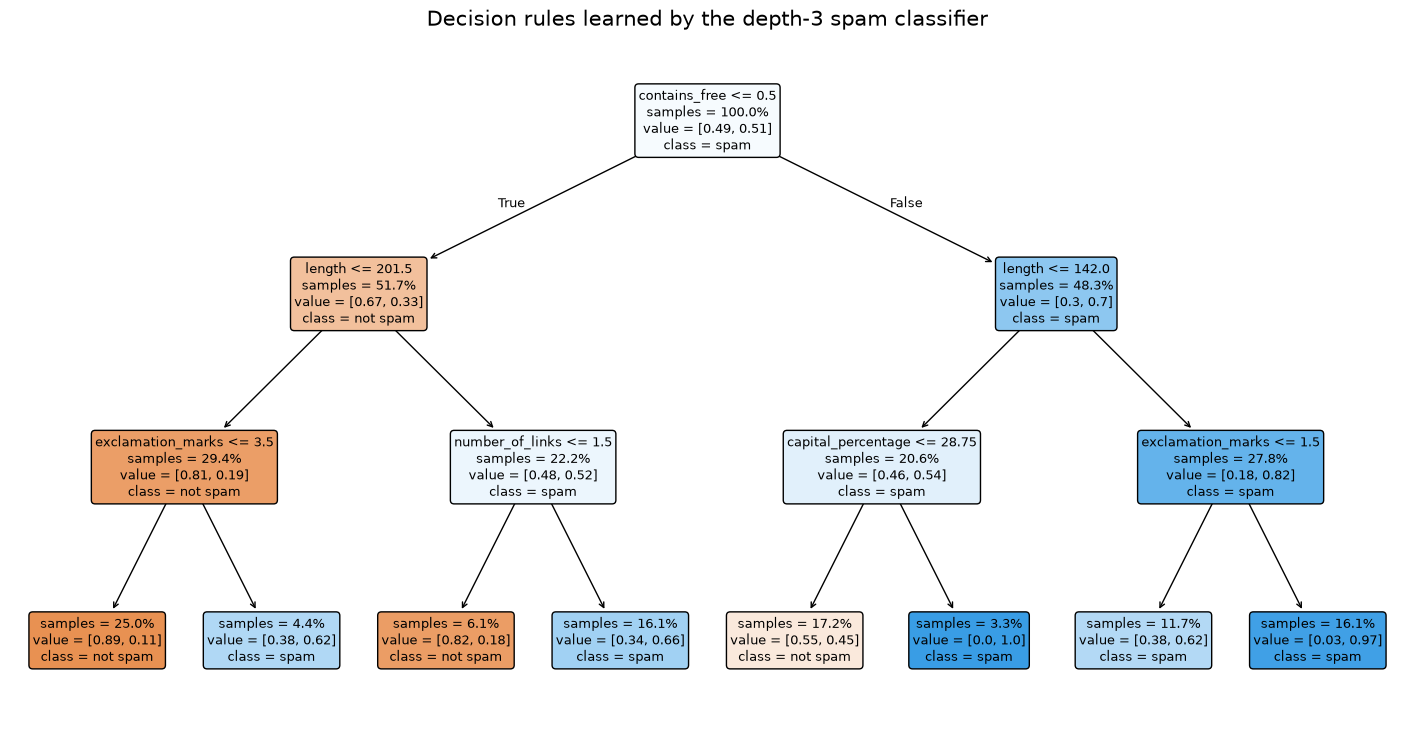

In [839]:
from sklearn.tree import plot_tree

# Match the class names to the numerical class order stored by the model.
class_name_lookup = {0: "not spam", 1: "spam"}
tree_class_names = [class_name_lookup[value] for value in classifier.classes_]

# Draw the fitted tree. The tree has at most three levels because max_depth=3.
plt.figure(figsize=(18, 9))
plot_tree(
    classifier,
    feature_names=feature_names,
    class_names=tree_class_names,
    filled=True,       # Color each node by its predicted class.
    rounded=True,      # Use rounded boxes for readability.
    impurity=False,    # Hide the advanced impurity calculation
    proportion=True,   # Show proportions rather than raw training counts.
    precision=2,
    fontsize=9,
)
plt.title("Decision rules learned by the depth-3 spam classifier", fontsize=15)
plt.show()

<div style="border-left: 5px solid #2563eb; background-color: #eff6ff;
            padding: 14px 18px; margin: 16px 0; border-radius: 4px;">

<p style="color:#1d4ed8; font-size:18px; font-weight:bold; margin:0 0 10px 0;">
How to read the tree
</p>

<ul style="font-size:16px; line-height:1.6; margin-bottom:0;">
  <li>Each non-leaf box contains a learned question, such as
      <code>contains_free &le; 0.5</code>.</li>
  <li>Follow the <strong>left branch</strong> when the condition is true and the
      <strong>right branch</strong> when it is false.</li>
  <li><code>samples</code> reports the proportion of training samples that reached the node.</li>
  <li><code>value</code> shows the proportions of not-spam and spam samples at the node, in that order.</li>
  <li><code>class</code> is the prediction made at the node. A box with no further branches is a
      <strong>leaf</strong> and makes the final prediction.</li>
  <li>The node color represents the predicted class. A stronger color means that one class is more
      dominant among the training samples reaching that node.</li>
</ul>

</div>

<div style="border-left: 5px solid #f59e0b; background-color:#fffbeb;
            padding: 12px 16px; margin:16px 0; border-radius:4px;">

<p style="margin:0 0 8px 0;">
<strong>Important:</strong> These are not universal spam-detection rules. They are the rules learned
by this depth-3 tree from this particular synthetic training set.
</p>

<p style="margin:0;">
A different dataset, feature set, training/test split, or tree depth could produce different rules.
</p>

</div>

## Example 3: Generalization and Overfitting

**Overfitting** occurs when a model memorizes details of the training data but performs poorly on unseen data. To demonstrate overfitting, we compare two trees trained with the same features but **different depth**:

* **Limited tree (`max_depth=2`):** the tree can make only two levels of decisions. Restricting its depth reduces its flexibility and encourages it to learn broad patterns rather than many detailed rules. We use it as an example of a simpler model that may generalize better.
  
* **Unrestricted tree (`max_depth=None`):** the tree may continue adding decisions until its normal stopping conditions are reached. This flexibility can fit the training samples more closely, but it may also increase the risk of learning noise or training-specific details.

We train both models and compare their performance on both the training data and test data, as shown below. 

Note: choosing the optimal tree setting is beyond the scope of this assignment.

In [840]:
model_settings = {
    "limited tree (depth 2)": 2,
    "unrestricted tree": None,
}

overfitting_rows = []

for model_name, depth in model_settings.items():
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    model.fit(X_train, y_train)

    train_accuracy = (model.predict(X_train) == y_train.to_numpy()).mean()
    test_accuracy = (model.predict(X_test) == y_test.to_numpy()).mean()

    overfitting_rows.append({
        "model": model_name,
        "training accuracy": train_accuracy,
        "unseen accuracy": test_accuracy,
        "gap": train_accuracy - test_accuracy,
    })

overfitting_results = pd.DataFrame(overfitting_rows).set_index("model")
overfitting_results.round(3)

,training accuracy,unseen accuracy,gap
model,,,
limited tree (depth 2),0.694,0.783,-0.089
unrestricted tree,1.000,0.817,0.183


---

❓<span style="color:purple;">**Quick test**</span>: **Which model demonstrates overfitting based on the training and unseen-data accuracies?**

A. The limited tree only

B. The unrestricted tree only

C. Both trees demonstrate the same degree of overfitting

D. Neither tree, because the unrestricted tree has the higher unseen-data accuracy

<details> <summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"> <b>B. The unrestricted tree only.</b></p>

**Explanation**:

<p style="color:blue;">
The unrestricted tree fits the training samples almost perfectly but performs less well on unseen samples. The noticeably higher training score than unseen-data score indicates overfitting, and the gap suggests the model has learned training-specific details that do not generalize.  
</p>

<p style="color:blue;">
Instead, the limited tree does not show this pattern.
</p>

</details>

---

**Notice that**: the limited model scores slightly higher on the unseen samples than on its training sample. This does not mean that it learned from the test data. This can occur because of **sampling variation**. 

---

❓<span style="color:purple;">**Quick test**</span>: **Based on the results, which conclusion about model selection is most appropriate?**

A. Always select the limited tree because it has the smaller training–unseen gap

B. Always select the unrestricted tree because it has perfect training accuracy

C. Select either model because training and unseen-data accuracy are equally important 

D. Evaluate both models across additional validation runs before making the final selection, e.g. different training/unseen data splits, different random seeds, etc.

<details> <summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"> <b>D. Evaluate both models across additional validation runs before making the final selection.</b></p>

**Explanation**:

<p style="color:blue;">
The unrestricted tree has higher unseen-data accuracy in this split but also shows more overfitting. One run is not sufficient to identify the more reliable model. 
</p>

<p style="color:blue;">
The comparison should therefore be repeated using additional validation runs before selecting a model. Or we may even choose a different model, e.g. model with different value for <code>max-depth</code>.
</p>

</details>

---

## Example 4: The importance of data - wrong labels

**"Garbage in, Garbage out" — The quality of data is key**. It is not possible to compensate for bad data (e.g., wrong labels, biased samples).

**Tasks**: To demonstrate the importance of data, we copy the training data and deliberately **flip 30% of the training labels**. Instead, the labels of the unseen test data remain untouched. 

Then we train two models using the dataset **with and without corrupted labels**. And evaluate their performance on the test data. In this way, we can measure to what extent the wrongly labeled training data would affect the performance.

### <span style="color:blue"> Step 1 — Select the samples to corrupt their labels</span>

We first make a copy of the training data. Then we randomly select 30% of the sample positions, for which we will corrupt their labels. 

`replace=False` ensures that a position cannot be selected more than once.

In [841]:
rng = np.random.default_rng(SEED)

# Make an independent copy: changing this Series will not change y_train.
y_train_corrupted = y_train.copy()

# Calculate how many labels correspond to 30% of the training samples.
n_labels_to_flip = int(0.30 * len(y_train_corrupted))

# Select positions, not index labels, so iloc can use them in the next step.
positions_to_flip = rng.choice(
    len(y_train_corrupted),
    size=n_labels_to_flip,
    replace=False,          
)

print("Training samples:", len(y_train_corrupted))
print("Positions selected for corruption:", len(positions_to_flip))

Training samples: 180
Positions selected for corruption: 54


### <span style="color:blue"> Step 2 — Flip the selected binary labels </span>

The spam labels are binary: **0** means **not spam** and **1** means **spam**. For a binary value, `1 - label` reverses it: 0 becomes 1, and 1 becomes 0. The output table visualizes the selected samples and the label before and after flip.  

In [842]:
# flip the label of the selected samples
y_train_corrupted.iloc[positions_to_flip] = (
    1 - y_train_corrupted.iloc[positions_to_flip]
)

# Build a data frame to show the label before
# and after the flip
label_comparison = pd.DataFrame({
    "clean label": y_train,
    "corrupted label": y_train_corrupted,
})
label_comparison["label changed"] = (
    label_comparison["clean label"] != label_comparison["corrupted label"]
)

print("Labels actually changed:", int(label_comparison["label changed"].sum()))
display(label_comparison[label_comparison["label changed"]].head(10))

Labels actually changed: 54


,clean label,corrupted label,label changed
109,1,0,True
128,0,1,True
182,1,0,True
31,0,1,True
148,1,0,True
2,1,0,True
239,1,0,True
125,0,1,True
138,1,0,True
32,1,0,True


### <span style="color:blue"> Step 3 — Train the two models </span>

The models make use of the same setting: the same samples, `max_depth`, random seed, and same feature. Except **the clean model learns from the original labels, whereas the corrupted model learns from the deliberately damaged copy**. 

Keeping everything else the same isolates the effect of label quality.

In [843]:
# Train the first model using the original training data
clean_model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
clean_model.fit(X_train, y_train)

# Train the second model using the training data with corrupted labels
corrupted_model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
corrupted_model.fit(X_train, y_train_corrupted)

print("Both models have been trained.")

Both models have been trained.


### <span style="color:blue"> Step 4 — Evaluate both models on the same test data </span>

Neither model has seen the test data `X_test` during training, and the correct test labels in `y_test` were not
corrupted either. Comparing both models with the same test samples gives a fair measurement of how the training-label damage affected performance.

In [844]:
# Evaluate the first model on the test data
clean_predictions = clean_model.predict(X_test)
clean_accuracy = (clean_predictions == y_test.to_numpy()).mean()

# Evaluate the second model which is trained using the corrupted label on the test data
corrupted_predictions = corrupted_model.predict(X_test)
corrupted_accuracy = (corrupted_predictions == y_test.to_numpy()).mean()

# Display the accuracy for the two models
label_quality_results = pd.DataFrame({
    "training-label quality": ["clean labels", "30% corrupted labels"],
    "unseen accuracy": [clean_accuracy, corrupted_accuracy],
}).set_index("training-label quality")

label_quality_results.round(3)

,unseen accuracy
training-label quality,
clean labels,0.833
30% corrupted labels,0.733


---

❓<span style="color:purple;">**Quick test**</span>: **Based on the results, how did training-label quality affect the model's performance?**

A. It had no meaningful effect because both models used the same algorithm

B. It reduced unseen-data accuracy because incorrect labels misled the learning process

C. It improved generalization by giving the model more varied labels

D. It affected only training performance and had no effect on unseen-data performance

<details> <summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"> <b>B. It reduced unseen-data accuracy because incorrect labels misled the learning process.</b></p>

**Explanation**:

<p style="color:blue;">
With clean labels, unseen-data accuracy was 0.833; after 30% of the training labels were corrupted, it fell to 0.733. Poor-quality labels taught the model misleading patterns and reduced its ability to generalize.
</p>

</details>

---

## Example 5 - A supervised-learning pipeline: Regression

Classification predicts categories. **Regression** predicts a continuous numerical value.

### <span style="color:blue"> Synthesize a data set for package delivery time </span>

The code below synthesizes a dataset with labeled samples for a regression problem. Each row represents one delivery job with two input features (`distance_km` and `number_of_packages`) and one known target value (`delivery_minutes`):

* `distance_km`: the travel distance in kilometres to the delivery address. Longer journeys generally require more time.
  
* `number_of_packages`: the number of packages included in the delivery. Handling more packages can increase the delivery duration.

* `delivery_minutes`: the total delivery duration in minutes. This is the continuous **target** that the regression model will learn to predict.

In [845]:
rng = np.random.default_rng(SEED)
n_deliveries = 180

deliveries = pd.DataFrame({
    "distance_km": rng.uniform(1, 30, n_deliveries).round(1),
    "number_of_packages": rng.integers(1, 9, n_deliveries),
})
deliveries["delivery_minutes"] = (
    8
    + 1.4 * deliveries["distance_km"]
    + 1.8 * deliveries["number_of_packages"]
    + rng.normal(0, 4, n_deliveries)
).round(1)

deliveries.head()

,distance_km,number_of_packages,delivery_minutes
0,16.6,2,35.9
1,11.0,3,29.7
2,11.7,4,36.2
3,11.9,2,33.7
4,29.6,7,56.6


<div style="background-color:#f4f8ff;
            border-left:5px solid #3b82f6;
            border-radius:6px;
            padding:12px 16px;
            margin:12px 0;">
<b>💡 Key idea: Classification versus regression</b><br><br>

The same supervised-learning pipeline applies, but the <b>target type</b> changes.
In classification, the target is a <b>category</b>; here, the target is a
<b>continuous numerical value</b>—the delivery time. Therefore, this is a
<b>regression task</b> rather than a classification task.

</div>

### <span style="color:blue"> Step 1 - Separate the features from the target </span>

Tell the learning algorithm which columns represent the input features, and which column is the target and it must learn to predict.

* `X_delivery` contains the two input features.
  
* `y_delivery` contains the known delivery durations, which is the target.

In [846]:
# Input features
X_delivery = deliveries[["distance_km", "number_of_packages"]]

# Continuous target: the numerical value that the model should predict.
y_delivery = deliveries["delivery_minutes"]

print("Feature-table shape:", X_delivery.shape)
print("Target-vector shape:", y_delivery.shape)

Feature-table shape: (180, 2)
Target-vector shape: (180,)


There are 180 rows in both objects, so every sample has one known target value. The feature table has two columns because each delivery job is described by two input feature.

### <span style="color:blue"> Step 2 - Reserve unseen samples </span>

We will use 75% of the samples for training. The remaining 25% form the test set. The same row split is applied to both the features and their corresponding target values.

In [847]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_delivery,
    y_delivery,
    test_size=0.25,       # Reserve 25% of the samples as unseen-data for evaluation.
    random_state=SEED,    # Make this particular split reproducible.
)

print("Training samples:", len(Xd_train))
print("Unseen test samples:", len(Xd_test))

Training samples: 135
Unseen test samples: 45


The suffix `d` stands for delivery. `Xd_train` contains the sample features used to train the model, while `yd_train` contains their corresponding known delivery durations. 

Similarly, `Xd_test` contains the features of the unseen test samples, while `yd_test` contains their known durations for evaluating the model's predictions.

### <span style="color:blue"> Step 3 - Create and train a regression model </span>

Train a regression model which maps delivery features to a numerical duration. 

`DecisionTreeRegressor` is the regression counterpart of the decision tree classifier used earlier. **It still asks feature-based questions, but its leaves predict numerical values** instead of class labels. 

In [848]:
# Create a regression model.
regressor = DecisionTreeRegressor(max_depth=3, random_state=SEED)

# Learn the feature questions and numerical predictions from training samples.
regressor.fit(Xd_train, yd_train)

print("Regression model trained.")

Regression model trained.


<div style="
    background-color:#f4f8ff;
    border-left:5px solid #3b82f6;
    border-radius:6px;
    padding:14px 18px;
    margin:12px 0;
    line-height:1.6;
">

<b>🔧 What does the code do?</b>

<ul>
  <li><code>DecisionTreeRegressor(...)</code> creates an untrained regression model.</li>

  <li><code>max_depth=3</code> limits the tree to three levels of feature-based decisions, helping keep the learned rules relatively simple.</li>

  <li><code>random_state=SEED</code> makes the result reproducible.</li>

  <li><code>fit(Xd_train, yd_train)</code> trains the model using each training sample's features and corresponding known delivery duration.</li>
</ul>

<p>
After <code>fit()</code> finishes, the model contains learned feature-based rules and numerical predictions. However, completing training does not tell us how well the model generalizes.
</p>

<p>
In the next step, we evaluate the trained model by applying it to <code>Xd_test</code> and comparing its predictions with the known durations in <code>yd_test</code>.
</p>

</div>

### <span style="color:blue"> Step 4 - Predict and measure model performance </span>

**Purpose:** Apply the trained model to unseen test samples and measure its predictive performance.

For classification problems, **accuracy** is often used to measure performance. For regression problems, the target is continuous value, so an exact-match accuracy is generally not appropriate. Common regression metrics include **mean absolute error (MAE)**, **root mean squared error (RMSE)**, **R-squared** ($R^2$), etc. In this example, we use MAE. 

<div style="
    background-color:#f4f8ff;
    border-left:5px solid #3b82f6;
    border-radius:6px;
    padding:12px 16px;
    margin:12px 0;
">

🧮 <b>Calculating MAE</b>

1. **Predict** the delivery duration for each test sample.
2. Calculate the **absolute error** between the predicted and known duration.
3. **Average** the absolute errors across all test samples.

$$
\text{MAE}
=
\frac{1}{n}
\sum_{i=1}^{n}
\left|y_i-\hat{y}_i\right|
$$

<div style="
    background-color:#ecfdf5;
    border-left:5px solid #22c55e;
    border-radius:6px;
    padding:10px 14px;
    margin:12px 0;
    color:#166534;
">
<b>✅ Interpretation</b><br>
A smaller MAE indicates better predictive performance.
</div>

In [849]:
# predict the delivery time for each unseen test sample.
delivery_predictions = regressor.predict(Xd_test)

# Compute the absolute error between prediction and the known target value
absolute_errors = np.abs(delivery_predictions - yd_test.to_numpy())

# Calculate the mean absolute error for all test samples
average_absolute_error = absolute_errors.mean()

print(f"Mean absolute error: {average_absolute_error:.2f} minutes")

Mean absolute error: 3.58 minutes


A test MAE of 3.58 minutes means that, on average, the model's predictions differ from the known delivery durations by 3.58 minutes on this unseen test set. 

However, **this value alone is not sufficient to determine how well the model generalizes**—it needs context from the training MAE, ideally if we can compare with a simple baseline, and additional validation runs.

### <span style="color:blue"> Step 5 - Assess whether the model generalize well </span>

To assess whether the model generalize well, we make two comparisons:

1. **Training MAE versus test MAE:** similar values suggest that performance transfers from the training samples to unseen samples. A much larger test MAE would warn of overfitting.
   
2. **Decision tree versus a simple baseline:** the baseline always predicts the median duration from the training set. 

   The baseline represents a model that ignores the features and always predicts one typical training duration. A useful model should perform better than this simple strategy.

In [850]:
# 1. Measure performance on the samples used for training.
training_predictions = regressor.predict(Xd_train)
training_absolute_errors = np.abs(
    training_predictions - yd_train.to_numpy()
)
training_mae = training_absolute_errors.mean()

# 2. Create a simple baseline that always predicts one typical duration.
# The median is calculated from training targets, not from the test set.
baseline_duration = yd_train.median()
baseline_predictions = np.full(len(yd_test), baseline_duration)
baseline_absolute_errors = np.abs(
    baseline_predictions - yd_test.to_numpy()
)
baseline_mae = baseline_absolute_errors.mean()

# Compare the three MAE values in one table.
generalization_results = pd.DataFrame({
    "evaluation": [
        "decision tree on training samples",
        "decision tree on unseen test samples",
        "median baseline on unseen test samples",
    ],
    "MAE in minutes": [
        training_mae,
        average_absolute_error,
        baseline_mae,
    ],
})

generalization_results.set_index("evaluation").round(2)

,MAE in minutes
evaluation,
decision tree on training samples,4.02
decision tree on unseen test samples,3.58
median baseline on unseen test samples,11.04


---

❓<span style="color:purple;">**Quick test**</span>: **Which observations can be made from the MAE results? Select all that apply.**

A. The similar training and test MAEs indicate that there is no large generalization gap

B. The lower test MAE proves that the model learned from the test samples

C. The decision tree performs substantially better than always predicting the median training duration

D. The test MAE being slightly lower than the training MAE can occur due to sampling variation

<details> <summary>Click to reveal the answer</summary>

**Answer**:

<p style="color:blue;"> <b>A, C, and D.</b></p>

**Explanation**:

<p style="color:blue;">
A slightly lower test MAE can occur through sampling variation; it does not mean that the model learned from the test samples. 
</p>

</details>

---

<div style="
    background-color:#f4f8ff;
    border-left:5px solid #3b82f6;
    border-radius:6px;
    padding:12px 16px;
    margin:12px 0;
">
    
<b>✅ Conclusion</b><br>
    
These results provide encouraging evidence that the tree generalizes reasonably well to this
test set. 
    
<b>Note</b>: They do not prove that it will generalize equally well to every future dataset. A
stronger conclusion would require repeating the comparison across additional data splits.
</div>

### <span style="color:blue"> Step 6 - Inspect the trained regression model</span>

Training creates a decision tree containing learned feature questions and numerical predictions.
Because this tree has `max_depth=3`, its learned structure is small enough to inspect.

We will examine the fitted model in two forms:

1. a **text representation** of its learned rules;
   
3. a **graphical representation** of the complete tree.

<span style="color:blue"> **Display the learned rules as text** </span>

`export_text()` converts the fitted tree into nested, `if/else`-style rules. The indentation shows
how deeply a question appears in the tree.

In [851]:
from sklearn.tree import export_text

# Convert the fitted regression tree into readable decision rules.
regression_rules = export_text(
    regressor,
    feature_names=list(Xd_train.columns),
    decimals=2,
)

print("Rules learned from the delivery training samples: \n")
print(regression_rules)

Rules learned from the delivery training samples: 

|--- distance_km <= 14.10
|   |--- distance_km <= 8.75
|   |   |--- distance_km <= 1.75
|   |   |   |--- value: [11.17]
|   |   |--- distance_km >  1.75
|   |   |   |--- value: [23.50]
|   |--- distance_km >  8.75
|   |   |--- number_of_packages <= 4.50
|   |   |   |--- value: [28.62]
|   |   |--- number_of_packages >  4.50
|   |   |   |--- value: [36.08]
|--- distance_km >  14.10
|   |--- distance_km <= 23.35
|   |   |--- number_of_packages <= 6.50
|   |   |   |--- value: [40.46]
|   |   |--- number_of_packages >  6.50
|   |   |   |--- value: [47.05]
|   |--- distance_km >  23.35
|   |   |--- number_of_packages <= 5.50
|   |   |   |--- value: [50.83]
|   |   |--- number_of_packages >  5.50
|   |   |   |--- value: [59.35]



**Each rule asks whether a feature is below or above a learned threshold.**

For example, the tree first separate shorter and longer journeys using `distance_km`. The indentation shows which
question is asked next. A `value` at the end of a branch is the numerical delivery-time prediction for samples following that path.

<span style="color:blue">  **Visualize the fitted decision tree [optional]**</span>

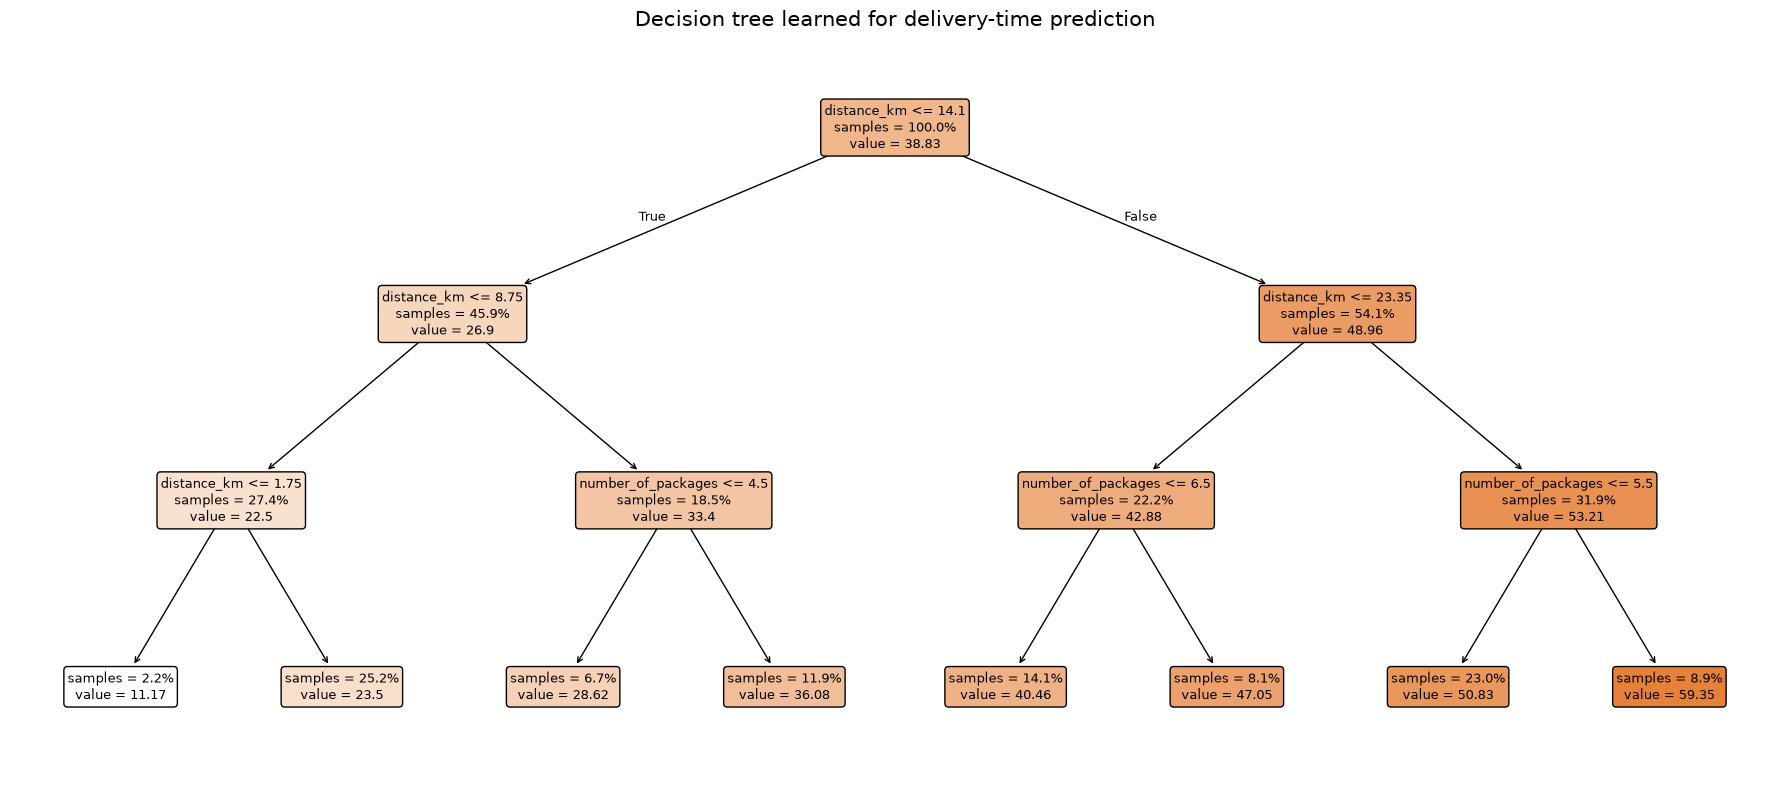

In [852]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    regressor,
    feature_names=list(Xd_train.columns),
    filled=True,       # Color nodes according to their predicted numerical values.
    rounded=True,      # Use rounded boxes to improve readability.
    impurity=False,    # Hide the advanced error calculation 
    proportion=True,   # Display sample proportions rather than raw counts.
    precision=2,
    fontsize=9,
)

plt.title("Decision tree learned for delivery-time prediction", fontsize=15)
plt.tight_layout()
plt.show()

<div style="background-color:#f4f8ff;border-left:5px solid #3b82f6;border-radius:6px;padding:12px 16px;margin:12px 0;line-height:1.6;">
<b>🔍 How to read the tree</b>

<ul>
  <li>Each internal node contains a learned feature question.</li>
  <li>Follow the left branch when the condition is true and the right branch when it is false.</li>
  <li><code>samples</code> shows the proportion of training samples reaching that node.</li>
  <li><code>value</code> shows the average delivery duration for those samples.</li>
  <li>At a leaf, <code>value</code> is the model's final predicted delivery duration.</li>
</ul>

These rules were learned from this synthetic training dataset. A different dataset, split, or
tree depth could produce a different model.
</div>

# 🏠 Assignment Questions<span style="color:blue;">[20 points]</span>

## <span style="color:blue;">[4 points]</span> Question 1 — Classification VS regression

### Q1-1: Each scenario below is a supervised-learning problem. Identify whether it is a **classification** or **regression** problem, and **justify your answer**.

1. Predict whether an image shows a cat, a dog, or a rabbit.
   
2. Predict the remaining battery life of a device in hours.

3. Predict whether a manufactured component will pass or fail a quality inspection.

4. Predict the water level of a river tomorrow in centimetres.

----
<div style="color:blue">
    
**Answer**: 
1. classification - because the task is about diffenetiating different objects into different classes 
2. regression - the target is a continuous value on a single device
3. classification - because the target is a discrete category
4. regression - the target is a continuous value on a single river
</div>

----


### Q1-2: The same input data can be used for different supervised-learning problems. 

1. In Q1-1, device measurements were used to predict the remaining battery life in hours. Suppose the target is changed to **low battery** or **sufficient battery**. What type of problem is it now?

2. What does this change show about what determines whether a supervised-learning problem is classification or regression?

----
<div style="color:blue">
    
**Answer**:
1. It becoems a classification problem, because we have multiple discrete targets
2. if the target is a continuous value, then the problem is a regression problem, and if we have multiple discrete targets, the problem becomes a  classification problem
</div>

----


## <span style="color:blue;">[6 points]</span> Question 2: Investigate how feature selection may affect model performance

> **Requirement:** To keep the comparison consistent, use `test_size=0.25`, `max_depth=3`, `random_state=SEED`, and `stratify=y` in the two cases. 

### Q2-1: Remove`capital_percentage` from the feature set. Train a depth-3 decision-tree classifier using the remaining features and report its unseen-data accuracy.

In [853]:
# insert your code here
no_percent_email = emails
no_percent_email = no_percent_email.drop(columns=["capital_percentage"])

feature_names = [
    "number_of_links",
    "contains_free",
    "length",
    "exclamation_marks",
]

X = no_percent_email[feature_names]  # Five input features for each email
y = no_percent_email["spam"]         # One known class label for each email

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,   # Keep 25% of the rows for the unseen-data check
    random_state=SEED,
    stratify=y,       # Keep similar spam proportions in both parts
)

classifier = DecisionTreeClassifier(max_depth=3, random_state=SEED)

# fit() is the training phase: the algorithm uses labeled samples.
classifier.fit(X_train, y_train)

# predict() is inference: the trained model is run on unseen feature rows.
test_predictions = classifier.predict(X_test)

correct = test_predictions == y_test.to_numpy()

# Python treats `True` as 1 and `False` as 0. Hence, 
# the mean gives the proportion of correct predictions
percentage_feature_test_accuracy = correct.mean()

training_predictions = classifier.predict(X_train)

# Compare the training predictions with their known labels.
training_correct = training_predictions == y_train.to_numpy()
training_accuracy_percentage = training_correct.mean()

print(f"Training accuracy: {training_accuracy_percentage:.3f}")
print(f"test accuracy: {percentage_feature_test_accuracy:.3f}")



Training accuracy: 0.778
test accuracy: 0.833


### Q2-2: Remove`contains_free` from the feature set. Train a depth-3 decision-tree classifier using the remaining features and report its unseen-data accuracy.

In [854]:
# insert your code here
no_free_email = emails
no_free_email = no_free_email.drop(columns=["contains_free"])

feature_names = [
    "number_of_links",
    "capital_percentage",
    "length",
    "exclamation_marks",
]

X = no_free_email[feature_names]  # Five input features for each email
y = no_free_email["spam"]         # One known class label for each email

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,   # Keep 25% of the rows for the unseen-data check
    random_state=SEED,
    stratify=y,       # Keep similar spam proportions in both parts
)

classifier = DecisionTreeClassifier(max_depth=3, random_state=SEED)

# fit() is the training phase: the algorithm uses labeled samples.
classifier.fit(X_train, y_train)

# predict() is inference: the trained model is run on unseen feature rows.
test_predictions = classifier.predict(X_test)

correct = test_predictions == y_test.to_numpy()

# Python treats `True` as 1 and `False` as 0. Hence, 
# the mean gives the proportion of correct predictions
free_feature_test_accuracy = correct.mean()

training_predictions = classifier.predict(X_train)

# Compare the training predictions with their known labels.
training_correct = training_predictions == y_train.to_numpy()
training_accuracy_free = training_correct.mean()

print(f"Training accuracy: {training_accuracy_free:.3f}")
print(f"test accuracy: {free_feature_test_accuracy:.3f}")

Training accuracy: 0.756
test accuracy: 0.667


### Q2-3: Display the test accuracy for the following 3 models in a single table:

1. the original five-feature model;
   
2. the model without `capital_percentage`; and
   
3. the model without `contains_free`.

In [855]:
# insert your code here
q2_results = pd.DataFrame({
    "model": [
        "original five-feature model",
        "without capital_percentage",
        "without contains_free",
    ],
    "test accuracy": [
        five_feature_test_accuracy,
        percentage_feature_test_accuracy,
        free_feature_test_accuracy,
    ],
}).set_index("model")
q2_results.round(3)


,test accuracy
model,
original five-feature model,0.833
without capital_percentage,0.833
without contains_free,0.667


### Q2-4: Based on the result in Q2-3, answer which feature's removal had the greater effect on unseen-data accuracy? Explain your answer and support your answer with numeric values.

----
<div style="color:blue">
    
**Answer**: Removing the contains_free feature had the greater effect on unseen-data accuracy. Compared to the original five-feature model's test accuracy of 0.833, removing capital_percentage left the test accuracy unchanged at 0.833 (a difference of 0.000), whereas removing contains_free caused the test accuracy to drop to 0.667 (a decrease of 0.167). This shows that contains_free provides much stronger predictive signal for the depth-3 decision tree to generalize to unseen emails than capital_percentage.
</div>

----


## <span style="color:blue;">[10 points]</span> Question 3: Explore how different test size may affect performance 

### Q3-1: train the decision tree with different training and test data split (0.1, 0.2, 0.3, 0.4, 0.5) and compare the training accuracy and test accuarcy.

<span style="color:blue;"> **Requirements:** </span>

Use the following test proportions: `test_proportions = [0.1, 0.2, 0.3, 0.4, 0.5]`. Each value specifies the proportion of the complete dataset reserved for the **test set**.

**For each test proportion**

1. Split the dataset into training and test sets.
   
2. Create and train a new depth-3 decision-tree classifier.

3. Evaluate the model on both the training and test sets.

4. Record the following results:

| Result | Meaning |
|---|---|
| **Test proportion** | Proportion of the complete dataset reserved for testing |
| **Training samples** | Number of samples in the training set |
| **Test samples** | Number of samples in the test set |
| **Training accuracy** | Accuracy obtained on the training samples |
| **Test accuracy** | Accuracy obtained on the unseen test samples |

> **Note:** To keep the comparison consistent, use the same five feature set, `max_depth=3`, `random_state=SEED`, and `stratify=y` in every case. Only the test proportion should change.

**Expected output**: Display one results table containing **one row for each test proportion**.

In [856]:
# Use the following test proportions:
test_proportions  = [0.1, 0.2, 0.3, 0.4, 0.5]

feature_names = [
    "number_of_links",
    "capital_percentage",
    "contains_free",
    "length",
    "exclamation_marks",
]

# Features and target label
X = emails[feature_names]  
y = emails["spam"]  

result_rows = []

# insert your code here
for proportion in test_proportions:
    X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=proportion,   # Keep 25% of the rows for the unseen-data check
    random_state=SEED,
    stratify=y,       # Keep similar spam proportions in both parts
)
    classifier = DecisionTreeClassifier(max_depth=3, random_state=SEED)

    # fit() is the training phase: the algorithm uses labeled samples.
    classifier.fit(X_train, y_train)

    # predict() is inference: the trained model is run on unseen feature rows.
    test_predictions = classifier.predict(X_test)
    training_predictions = classifier.predict(X_train)

    correct = test_predictions == y_test.to_numpy()
    correct_train = training_predictions == y_train.to_numpy()

    five_feature_test_accuracy = correct.mean()
    five_feature_train_accuracy = correct_train.mean()
    
    result_rows.append({
        "Test proportion": proportion,
        "Training samples": len(X_train),
        "Test samples": len(X_test),
        "Training accuracy": five_feature_train_accuracy,
        "Test accuracy": five_feature_test_accuracy,
        })

q3_results = pd.DataFrame(result_rows)
q3_results.round({"Training accuracy": 3, "Test accuracy": 3})


,Test proportion,Training samples,Test samples,Training accuracy,Test accuracy
0,0.1,216,24,0.769,0.875
1,0.2,192,48,0.766,0.833
2,0.3,168,72,0.768,0.806
3,0.4,144,96,0.757,0.656
4,0.5,120,120,0.750,0.667


### Q3-2:  As the test proportion increases, what happens to the numbers of training and test samples? Explain the reason behind the observed trend? 

----
<div style="color:blue">
    
**Answer**: As the test proportion increases from 0.1 to 0.5, the number of test samples increases (from 24 to 120) while the number of training samples decreases (from 216 to 120). This happens because the total dataset size is fixed at 240 emails, so allocating a larger fraction to the test set leaves a smaller fraction for training.

</div>

----


### Q3-3: based on these particular results, which test proportion(s) shows evidence for potential overfitting? Justify your answer and support your answer with numeric values.

----
<div style="color:blue">
    
**Answer**: The 0.4 test proportion shows the strongest evidence of potential overfitting, as its training accuracy (0.757) exceeds its test accuracy (0.656) by 0.101 (with 0.5 also showing a smaller positive gap of 0.750 vs. 0.667). Proportions 0.1–0.3 do not indicate overfitting because their test accuracies (0.875, 0.833, 0.806) are actually higher than their training accuracies (0.769, 0.766, 0.768).
</div>

----


### Q3-4: What overall pattern do you observe in training accuracy as the test proportion increases? Does it show a clear increasing or decreasing trend, or does it remain relatively stable with small fluctuations? Explain your answer and support your answer with numeric values.

----
<div style="color:blue">
    
**Answer**: Training accuracy remains relatively stable with small fluctuations, staying within a narrow range from 0.769 at 0.1 to 0.750 at 0.5 (0.769, 0.766, 0.768, 0.757, 0.750). This occurs because max_depth=3 limits the decision tree's complexity, keeping its fit on the training set fairly consistent across these sample sizes.
</div>

----


### Q3-5:  1) What overall pattern do you observe in test accuracy as the test proportion increases? Does it show a clear increasing or decreasing trend, or does it remain relatively stable with small fluctuations? Explain your answer and support your answer with numeric values. 2) What could be one possible cause for the observed trend. 

----
<div style="color:blue">
    
**Answer**: 
1. Test accuracy shows a clear overall decreasing trend as the test proportion increases, dropping from 0.875 at 0.1 to 0.833 (0.2), 0.806 (0.3), 0.656 (0.4), and 0.667 (0.5). 
2. One possible cause is that larger test proportions leave fewer training samples (decreasing from 216 to 120), giving the model less data to learn generalizable patterns (along with sampling variation across splits).


</div>

----
